# **Calibration Analysis**

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## **Section 1: Config**

In [2]:
import os
import io
import json
import contextlib
import platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

drive_dir = '/content/drive/MyDrive/projectMushroom'
os.chdir(drive_dir)
import src.test as test_utils
import src.ensembleVoting as ensembleVoting
import src.mcnemarTest as mcnemarTest
import src.visualization as visualization

DATASETS = {'MushroomA': 'Mushroom A', 'MushroomB': 'Mushroom B'}
N_FOLDS = 5
WEIGHT_TYPE = 'best'

MODELS = [
    ('ConvNeXt-T',   'modelWeights',   'convnext_tiny_224_r1_v1'),
    ('MarisaNeXt-T', 'myModelWeights', 'convnext_tiny_modify_D6_224_r1_v1'),
]
BASELINE, PROPOSED = 'ConvNeXt-T', 'MarisaNeXt-T'
MODES = ['Single', 'Ensemble']

N_BINS = 15
N_GRADCAM_SHOWN = 9

OUT_DIR = f'{drive_dir}/addition/calibration'
os.makedirs(OUT_DIR, exist_ok=True)

def model_dir(weights_root, name, ds):
    return f'{drive_dir}/{weights_root}/{ds}/{name}_{ds}'

try:
    FONT = visualization.matplotlib_font(font_dir=f'{drive_dir}/assets/fonts', prefer_name='Times-Roman')
except (FileNotFoundError, RuntimeError) as e:
    FONT = matplotlib.rcParams['font.family']
    print(f'[Warning] {e} -> using the default font')
FONTSIZE = 14
print(f'Font: {FONT}')
print(f'Output directory: {OUT_DIR}')

Font: OPTITimes-Roman
Output directory: /content/drive/MyDrive/projectMushroom/addition/calibration


## **Section 2: Load Logs and Cross-check**

In [3]:
def read_csv(path, **kwargs):
    if not os.path.exists(path):
        raise FileNotFoundError(f'[Error] File not found: {path}')
    return pd.read_csv(path, **kwargs)

def read_json(path):
    if not os.path.exists(path):
        raise FileNotFoundError(f'[Error] File not found: {path}')
    with open(path) as f:
        return json.load(f)

def quiet(fn, *args, **kwargs):
    with contextlib.redirect_stdout(io.StringIO()):
        return fn(*args, **kwargs)

def read_fold_csv(d, k, kind):
    return read_csv(f'{d}/fold_{k}/fold_{k}_{kind}_{WEIGHT_TYPE}_weight.csv', float_precision='round_trip').iloc[0]

def check(name, expected, actual, tol=1e-9):
    if not np.isclose(expected, actual, atol=tol, rtol=0):
        raise AssertionError(f'[Error] {name}: saved = {actual}, recomputed = {expected}')

def check_equal(name, expected, actual):
    if expected != actual:
        raise AssertionError(f'[Error] {name}: saved = {actual}, recomputed = {expected}')

def path_key(path):
    return (os.path.basename(os.path.dirname(str(path))), os.path.basename(str(path)))

def select_best_fold(val_perf):
    best = None
    for k, perf in enumerate(val_perf, start=1):
        key = (perf['accuracy'], -perf['loss'])
        if best is None or key > best[0]:
            best = (key, k)
    return best[1]

In [4]:
RUNS = {}
for label, weights_root, name in MODELS:
    for ds in DATASETS:
        d = model_dir(weights_root, name, ds)
        y_true, filepaths, idx_to_class = quiet(ensembleVoting.load_test_records, d, weight_type=WEIGHT_TYPE)
        fold_probs = quiet(ensembleVoting.load_fold_probs, d, N_FOLDS, weight_type=WEIGHT_TYPE)
        val_perf = [read_fold_csv(d, k, 'validate_perf') for k in range(1, N_FOLDS + 1)]
        test_perf = [read_fold_csv(d, k, 'test_perf') for k in range(1, N_FOLDS + 1)]
        ens_saved = read_csv(f'{d}/ensemble/ensem_test_probs_{WEIGHT_TYPE}_weight.csv').values
        ens_perf = read_csv(f'{d}/ensemble/ensem_test_perf_{WEIGHT_TYPE}_weight.csv', float_precision='round_trip').iloc[0]
        best_saved = read_json(f'{d}/summary/best_fold_info.json')['best_fold_num']

        if fold_probs.shape[1] != len(y_true):
            raise AssertionError(f'[Error] {label} {ds}: number of test samples differs')

        k = select_best_fold(val_perf)
        check_equal(f'{label} {ds} best fold vs best_fold_info.json', k, best_saved)

        for j in range(N_FOLDS):
            _, m = quiet(test_utils.evaluate_preds, y_true=y_true, y_probs=fold_probs[j], task='multiclass', average='macro')
            for met in ['loss', 'accuracy']:
                check(f'{label} {ds} fold {j + 1} {met}', m[met], test_perf[j][met])

        ens_probs = ensembleVoting.soft_voting(fold_probs)
        if not np.allclose(ens_probs, ens_saved, rtol=0, atol=1e-6):
            raise AssertionError(f'[Error] {label} {ds}: recomputed ensemble probabilities differ from ensem_test_probs')
        _, m = quiet(test_utils.evaluate_preds, y_true=y_true, y_probs=ens_probs, task='multiclass', average='macro')
        check(f'{label} {ds} ensemble loss', m['loss'], ens_perf['loss'], tol=1e-6)
        check(f'{label} {ds} ensemble accuracy', m['accuracy'], ens_perf['accuracy'])

        RUNS[(label, ds)] = {
            'dir': d, 'y_true': y_true, 'filepaths': filepaths, 'keys': [path_key(p) for p in filepaths],
            'idx_to_class': idx_to_class, 'fold_probs': fold_probs, 'best_fold': k,
            'probs': {'Single': fold_probs[k - 1], 'Ensemble': ens_probs},
        }
        print(f'[Logs] {label} {ds}: n = {len(y_true)} | best fold = {k} | all checks passed')

for ds in DATASETS:
    a, b = RUNS[(BASELINE, ds)], RUNS[(PROPOSED, ds)]
    check_equal(f'{ds} test images (baseline vs proposed)', a['keys'], b['keys'])
    if not np.array_equal(a['y_true'], b['y_true']):
        raise AssertionError(f'[Error] {ds}: true labels differ between models')
print('[Logs] Both models share the same test images and labels on every dataset')

[Logs] ConvNeXt-T MushroomA: n = 1326 | best fold = 2 | all checks passed
[Logs] ConvNeXt-T MushroomB: n = 600 | best fold = 4 | all checks passed
[Logs] MarisaNeXt-T MushroomA: n = 1326 | best fold = 2 | all checks passed
[Logs] MarisaNeXt-T MushroomB: n = 600 | best fold = 4 | all checks passed
[Logs] Both models share the same test images and labels on every dataset


## **Section 3: Metric Functions**

In [5]:
def clean_probs(probs):
    p = np.clip(np.asarray(probs, dtype=np.float64), 1e-15, None)
    return p / p.sum(axis=1, keepdims=True)

def per_sample(probs, y_true):
    p = clean_probs(probs)
    conf, pred = p.max(axis=1), p.argmax(axis=1)
    onehot = np.eye(p.shape[1])[y_true]
    return {
        'conf': conf,
        'pred': pred,
        'correct': (pred == y_true).astype(np.float64),
        'nll': -np.log(p[np.arange(len(y_true)), y_true]),
        'brier': ((p - onehot) ** 2).sum(axis=1),
    }

def bin_index(conf, n_bins=N_BINS):
    edges = np.linspace(0.0, 1.0, n_bins + 1)
    return np.clip(np.digitize(conf, edges[1:-1], right=True), 0, n_bins - 1)

def ece(conf, correct, n_bins=N_BINS):
    idx = bin_index(conf, n_bins)
    s_conf = np.bincount(idx, weights=conf, minlength=n_bins)
    s_acc = np.bincount(idx, weights=correct, minlength=n_bins)
    return float(np.abs(s_acc - s_conf).sum() / len(conf))

def reliability_table(conf, correct, n_bins=N_BINS):
    idx = bin_index(conf, n_bins)
    edges = np.linspace(0.0, 1.0, n_bins + 1)
    rows = []
    for b in range(n_bins):
        m = idx == b
        rows.append({'bin': b + 1, 'lower': edges[b], 'upper': edges[b + 1], 'count': int(m.sum()),
                     'mean_confidence': float(conf[m].mean()) if m.any() else np.nan,
                     'accuracy': float(correct[m].mean()) if m.any() else np.nan})
    return pd.DataFrame(rows)

In [6]:
rng = np.random.default_rng(0)
_conf = rng.uniform(0.5, 1.0, 200_000)
_correct = (rng.uniform(size=_conf.size) < _conf).astype(float)
assert ece(_conf, _correct) < 0.01, 'ECE of a calibrated synthetic model should be ~0'
_over = np.clip(_conf + 0.05, None, 1.0)
assert abs(ece(_over, _correct) - 0.05) < 0.01, 'ECE should recover a 0.05 confidence shift'
print('[Logs] Metric sanity checks passed')

[Logs] Metric sanity checks passed


## **Section 4: Calibration on the Test Set**

In [7]:
SAMPLES, ROWS, REL = {}, [], []
for ds in DATASETS:
    for label, *_ in MODELS:
        run = RUNS[(label, ds)]
        for mode in MODES:
            s = per_sample(run['probs'][mode], run['y_true'])
            _, m = quiet(test_utils.evaluate_preds, y_true=run['y_true'], y_probs=run['probs'][mode], task='multiclass', average='macro')
            check(f'{label} {ds} {mode} NLL vs evaluate_preds', s['nll'].mean(), m['loss'], tol=1e-9)
            check(f'{label} {ds} {mode} accuracy vs evaluate_preds', s['correct'].mean(), m['accuracy'])
            SAMPLES[(ds, label, mode)] = s
            ROWS.append({'dataset': ds, 'model': label, 'mode': mode,
                         'fold': run['best_fold'] if mode == 'Single' else 'all',
                         'n_test': len(run['y_true']), 'n_errors': int((s['correct'] == 0).sum()),
                         'accuracy': s['correct'].mean(), 'mean_confidence': s['conf'].mean(),
                         'ece': ece(s['conf'], s['correct']), 'brier': s['brier'].mean(), 'nll': s['nll'].mean()})
            t = reliability_table(s['conf'], s['correct'])
            t.insert(0, 'mode', mode); t.insert(0, 'model', label); t.insert(0, 'dataset', ds)
            REL.append(t)

CAL = pd.DataFrame(ROWS)
REL = pd.concat(REL, ignore_index=True)
display(CAL.style.hide(axis='index').format(precision=4))

dataset,model,mode,fold,n_test,n_errors,accuracy,mean_confidence,ece,brier,nll
MushroomA,ConvNeXt-T,Single,2,1326,52,0.9608,0.9721,0.0194,0.0640,0.1391
MushroomA,ConvNeXt-T,Ensemble,all,1326,40,0.9698,0.9574,0.0166,0.0477,0.1009
MushroomA,MarisaNeXt-T,Single,2,1326,60,0.9548,0.9719,0.0213,0.0722,0.1474
MushroomA,MarisaNeXt-T,Ensemble,all,1326,41,0.9691,0.9588,0.0150,0.0516,0.1083
MushroomB,ConvNeXt-T,Single,4,600,8,0.9867,0.9781,0.0108,0.0229,0.0666
MushroomB,ConvNeXt-T,Ensemble,all,600,6,0.9900,0.9818,0.0105,0.0166,0.0516
MushroomB,MarisaNeXt-T,Single,4,600,10,0.9833,0.9853,0.0075,0.0258,0.0648
MushroomB,MarisaNeXt-T,Ensemble,all,600,6,0.9900,0.9812,0.0140,0.0190,0.0517


## **Section 5: Every Fold Model (mean ± STD over 5 folds)**

In [8]:
FOLD_ROWS = []
for ds in DATASETS:
    for label, *_ in MODELS:
        run = RUNS[(label, ds)]
        for k in range(1, N_FOLDS + 1):
            s = per_sample(run['fold_probs'][k - 1], run['y_true'])
            FOLD_ROWS.append({'dataset': ds, 'model': label, 'fold': k, 'accuracy': s['correct'].mean(),
                              'ece': ece(s['conf'], s['correct']), 'brier': s['brier'].mean(), 'nll': s['nll'].mean()})
FOLDS = pd.DataFrame(FOLD_ROWS)
FOLD_SUMMARY = FOLDS.groupby(['dataset', 'model'])[['accuracy', 'ece', 'brier', 'nll']].agg(['mean', 'std'])
display(FOLD_SUMMARY.style.format(precision=4))

## **Section 6: Reliability Diagrams**

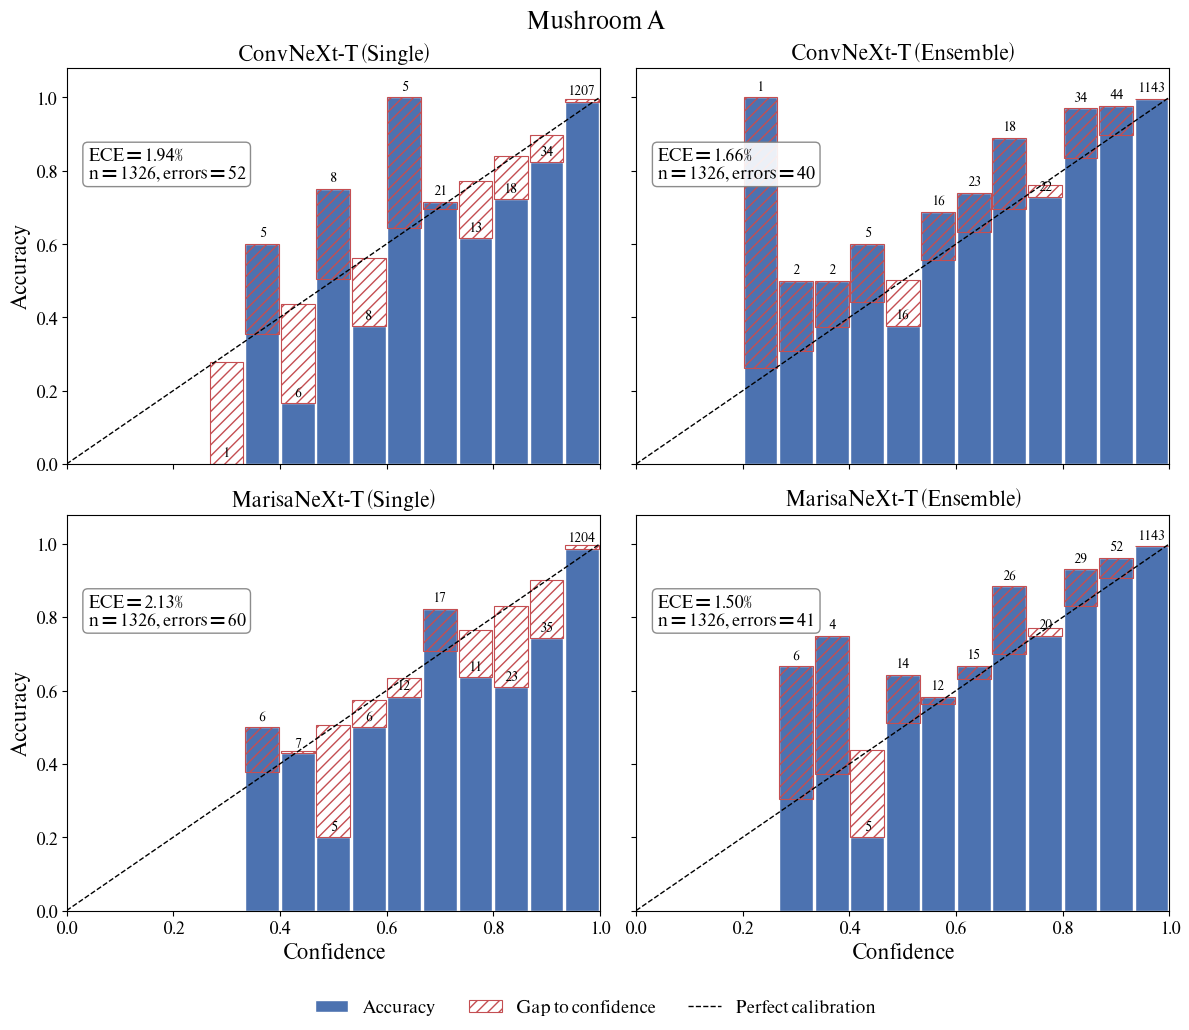

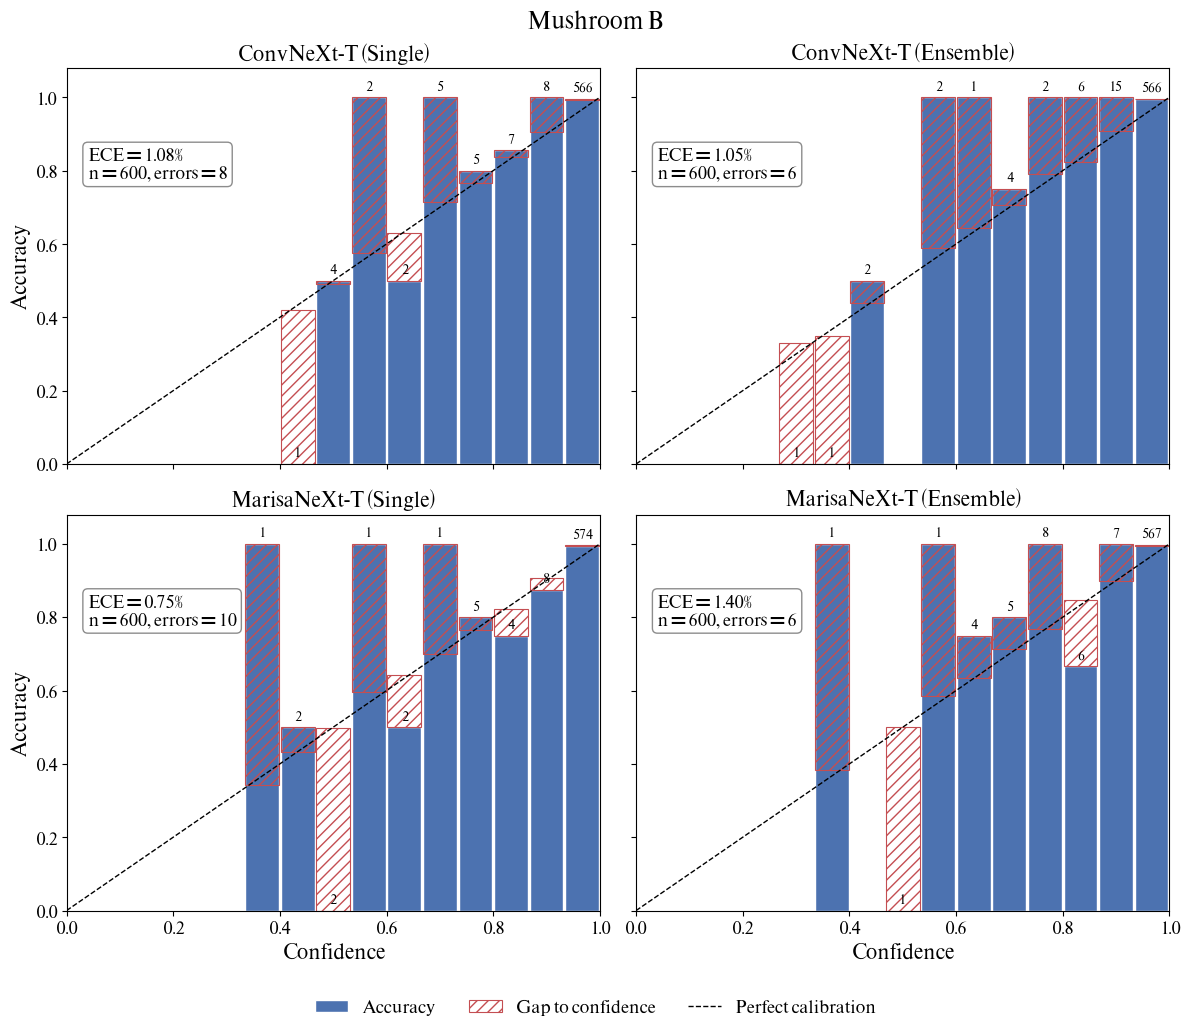

In [9]:
def plot_reliability(ds, fontsize=FONTSIZE, save_path=None):
    fig, axes = plt.subplots(len(MODELS), len(MODES), figsize=(6 * len(MODES), 5.2 * len(MODELS)), sharex=True, sharey=True)
    width = 1.0 / N_BINS
    for i, (label, *_) in enumerate(MODELS):
        for j, mode in enumerate(MODES):
            ax = axes[i, j]
            t = REL[(REL.dataset == ds) & (REL.model == label) & (REL['mode'] == mode)]
            t = t[t['count'] > 0]
            centers = (t['lower'] + t['upper']) / 2
            ax.bar(centers, t['accuracy'], width=width * 0.95, color='#4C72B0', edgecolor='white', label='Accuracy')
            ax.bar(centers, t['mean_confidence'] - t['accuracy'], bottom=t['accuracy'], width=width * 0.95,
                   color='none', edgecolor='#C44E52', hatch='///', linewidth=0.8, label='Gap to confidence')
            ax.plot([0, 1], [0, 1], linestyle='--', color='black', linewidth=1)
            for x, y, n in zip(centers, t['accuracy'], t['count']):
                ax.text(x, min(y, 1.0) + 0.015, str(n), ha='center', va='bottom', fontsize=fontsize - 5)
            r = CAL[(CAL.dataset == ds) & (CAL.model == label) & (CAL['mode'] == mode)].iloc[0]
            ax.text(0.04, 0.80, f"ECE = {100 * r.ece:.2f}%\nn = {r.n_test}, errors = {r.n_errors}",
                    transform=ax.transAxes, va='top', fontsize=fontsize - 2,
                    bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='grey', alpha=0.9), zorder=5)
            ax.set_title(f'{label} ({mode})', fontsize=fontsize)
            ax.set_xlim(0, 1); ax.set_ylim(0, 1.08)
            if i == len(MODELS) - 1: ax.set_xlabel('Confidence', fontsize=fontsize)
            if j == 0: ax.set_ylabel('Accuracy', fontsize=fontsize)
            ax.tick_params(labelsize=fontsize - 2)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    handles.append(plt.Line2D([0], [0], linestyle='--', color='black', linewidth=1)); labels.append('Perfect calibration')
    fig.suptitle(DATASETS[ds], fontsize=fontsize + 2)
    fig.tight_layout(rect=(0, 0.05, 1, 1))
    fig.legend(handles, labels, loc='lower center', ncol=3, fontsize=fontsize - 2, frameon=False)
    if save_path:
        fig.savefig(f'{save_path}.png', format='png', dpi=300, bbox_inches='tight')
        fig.savefig(f'{save_path}.svg', format='svg', bbox_inches='tight')
    plt.show()

for ds in DATASETS:
    plot_reliability(ds, save_path=f'{OUT_DIR}/reliability_{ds}')

## **Section 7: Mushroom B Errors by Edibility**

In [10]:
def edibility(name):
    return name.rsplit('-', 1)[-1]

SAFETY = []
ds = 'MushroomB'
for label, *_ in MODELS:
    run = RUNS[(label, ds)]
    for mode in MODES:
        s = SAMPLES[(ds, label, mode)]
        for i in np.nonzero(s['correct'] == 0)[0]:
            true_c, pred_c = run['idx_to_class'][int(run['y_true'][i])], run['idx_to_class'][int(s['pred'][i])]
            SAFETY.append({'model': label, 'mode': mode, 'image': '/'.join(run['keys'][i]), 'true': true_c, 'pred': pred_c,
                           'confidence': s['conf'][i], 'direction': f'{edibility(true_c)} -> {edibility(pred_c)}'})
SAFETY = pd.DataFrame(SAFETY)
display(SAFETY.sort_values(['model', 'mode', 'confidence'], ascending=[True, True, False]).style.hide(axis='index').format(precision=4))
danger = SAFETY[SAFETY['direction'] == 'NotEdible -> Edible']
print(f'[Logs] Not-edible images predicted as edible: {len(danger)} rows over {len(MODELS) * len(MODES)} model/mode combinations')

model,mode,image,true,pred,confidence,direction
ConvNeXt-T,Ensemble,Gyromitra_Esculenta-NotEdible/Gyromitra_Esculenta_0016.jpg,Gyromitra_Esculenta-NotEdible,Morchella_Deliciosa-Edible,0.9982,NotEdible -> Edible
ConvNeXt-T,Ensemble,Clitocybe_Costata-Edible/Clitocybe_Costata_0104.jpg,Clitocybe_Costata-Edible,Entoloma_Lividum-NotEdible,0.9744,Edible -> NotEdible
ConvNeXt-T,Ensemble,Amanita_Citrina-Edible/Amanita_Citrina_0149.jpg,Amanita_Citrina-Edible,Amanita_Pantherina-NotEdible,0.7108,Edible -> NotEdible
ConvNeXt-T,Ensemble,Hydnum_Rufescens-NotEdible/Hydnum_Rufescens_0095.jpg,Hydnum_Rufescens-NotEdible,Amanita_Caesarea-Edible,0.4629,NotEdible -> Edible
ConvNeXt-T,Ensemble,Clitocybe_Costata-Edible/Clitocybe_Costata_0043.jpg,Clitocybe_Costata-Edible,Omphalotus_Olearius-NotEdible,0.3495,Edible -> NotEdible
ConvNeXt-T,Ensemble,Russula_Cyanoxantha-Edible/Russula_Cyanoxantha_0176.jpg,Russula_Cyanoxantha-Edible,Russula_Delica-NotEdible,0.3307,Edible -> NotEdible
ConvNeXt-T,Single,Gyromitra_Esculenta-NotEdible/Gyromitra_Esculenta_0016.jpg,Gyromitra_Esculenta-NotEdible,Morchella_Deliciosa-Edible,0.9972,NotEdible -> Edible
ConvNeXt-T,Single,Clitocybe_Costata-Edible/Clitocybe_Costata_0104.jpg,Clitocybe_Costata-Edible,Entoloma_Lividum-NotEdible,0.9758,Edible -> NotEdible
ConvNeXt-T,Single,Phallus_Impudicus-NotEdible/Phallus_Impudicus_0031.jpg,Phallus_Impudicus-NotEdible,Morchella_Deliciosa-Edible,0.8384,NotEdible -> Edible
ConvNeXt-T,Single,Clitocybe_Costata-Edible/Clitocybe_Costata_0027.jpg,Clitocybe_Costata-Edible,Hydnum_Rufescens-NotEdible,0.7770,Edible -> NotEdible


[Logs] Not-edible images predicted as edible: 8 rows over 4 model/mode combinations


## **Section 8: Confidence of the Grad-CAM Images**

In [11]:
GRADCAM = []
for ds in DATASETS:
    ul = read_csv(f'{drive_dir}/data/{ds}/unique_label.csv')
    for label, *_ in MODELS:
        run = RUNS[(label, ds)]
        pos = {key: i for i, key in enumerate(run['keys'])}
        for r_i, fp in enumerate(ul['Filepaths']):
            key = path_key(fp)
            if key not in pos:
                raise AssertionError(f'[Error] {ds}: Grad-CAM image {key} is not in the test set')
            i = pos[key]
            for mode in MODES:
                s = SAMPLES[(ds, label, mode)]
                GRADCAM.append({'dataset': ds, 'model': label, 'mode': mode, 'row': r_i,
                                'shown_in_gradcam_figure': r_i < N_GRADCAM_SHOWN, 'image': '/'.join(key),
                                'true': run['idx_to_class'][int(run['y_true'][i])],
                                'pred': run['idx_to_class'][int(s['pred'][i])],
                                'correct': bool(s['correct'][i]), 'confidence': s['conf'][i]})
GRADCAM = pd.DataFrame(GRADCAM)
display(GRADCAM[GRADCAM['mode'] == 'Single'].style.hide(axis='index').format(precision=4))
print('[Logs] Single = best fold, the same model used for the Grad-CAM figures (get_best_model_on_validate_set)')

dataset,model,mode,row,shown_in_gradcam_figure,image,true,pred,correct,confidence
MushroomA,ConvNeXt-T,Single,0,True,Entoloma/385_3iniw1mVko0.jpg,Entoloma,Entoloma,True,0.9696
MushroomA,ConvNeXt-T,Single,1,True,Boletus/0993_YMPWY3nZZsM.jpg,Boletus,Boletus,True,0.9952
MushroomA,ConvNeXt-T,Single,2,True,Lactarius/310_MVmkt2VWorA.jpg,Lactarius,Lactarius,True,0.9989
MushroomA,ConvNeXt-T,Single,3,True,Amanita/290_8VTdQ2j5LL0.jpg,Amanita,Amanita,True,0.9998
MushroomA,ConvNeXt-T,Single,4,True,Russula/433_P89n7ud6bLI.jpg,Russula,Russula,True,0.9998
MushroomA,ConvNeXt-T,Single,5,True,Cortinarius/540_r5xzAIMgEGo.jpg,Cortinarius,Cortinarius,True,0.9994
MushroomA,ConvNeXt-T,Single,6,True,Agaricus/351_mHFbGn8oQ3M.jpg,Agaricus,Agaricus,True,0.9996
MushroomA,ConvNeXt-T,Single,7,True,Hygrocybe/172_o-_VYiEsJkI.jpg,Hygrocybe,Hygrocybe,True,0.9984
MushroomA,ConvNeXt-T,Single,8,True,Suillus/231__NpqweN7EqA.jpg,Suillus,Suillus,True,0.9975
MushroomA,MarisaNeXt-T,Single,0,True,Entoloma/385_3iniw1mVko0.jpg,Entoloma,Entoloma,True,0.9925


[Logs] Single = best fold, the same model used for the Grad-CAM figures (get_best_model_on_validate_set)


## **Section 9: Save Results**

In [12]:
CAL.to_csv(f'{OUT_DIR}/calibration_summary.csv', index=False)
REL.to_csv(f'{OUT_DIR}/reliability_bins.csv', index=False)
FOLDS.to_csv(f'{OUT_DIR}/calibration_per_fold.csv', index=False)
SAFETY.to_csv(f'{OUT_DIR}/mushroomB_errors_by_edibility.csv', index=False)
GRADCAM.to_csv(f'{OUT_DIR}/gradcam_images_confidence.csv', index=False)
with open(f'{OUT_DIR}/run_info.json', 'w') as f:
    json.dump({'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
               'n_bins': N_BINS,
               'models': {label: model_dir(w, n, '<dataset>') for label, w, n in MODELS},
               'best_fold': {f'{label} {ds}': RUNS[(label, ds)]['best_fold'] for label, *_ in MODELS for ds in DATASETS}},
              f, indent=2)
print(f'[Logs] Saved results to {OUT_DIR}:')
for name in sorted(os.listdir(OUT_DIR)):
    print(f'  - {name}')

[Logs] Saved results to /content/drive/MyDrive/projectMushroom/addition/calibration:
  - calibration_per_fold.csv
  - calibration_summary.csv
  - gradcam_images_confidence.csv
  - mushroomB_errors_by_edibility.csv
  - reliability_MushroomA.png
  - reliability_MushroomA.svg
  - reliability_MushroomB.png
  - reliability_MushroomB.svg
  - reliability_bins.csv
  - run_info.json
